# 4 · Plant One Itemset

Put one pattern into the baskets **on purpose and exactly**: "2.00% of baskets hold tea and sugar", and the data
then says precisely that. Later, when the model claims something goes together, we can check it against what we made.

Method: pick the items → work out how many baskets that is → top up random baskets that don't already hold the set.

**Done when:** `my_plant_itemset` hits the target exactly and is identical to the reference, basket for basket.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from thilimarketbasket.generate import (
    Planted, make_catalog, popularity, background_baskets, find_items, support_of, plant_itemset as reference_plant)
from thilimarketbasket.mine import frequent_itemsets

catalog = make_catalog()
shares = popularity(catalog)
index = {item.name: i for i, item in enumerate(catalog)}
baskets = background_baskets(100_000, catalog, shares, seed=0)
print(f"{len(baskets):,} background baskets")

100,000 background baskets


## Choose the items

Tea and sugar — but which SKUs? Ask the catalogue what this shop stocks.

In [2]:
for product in ("Tea Powder", "Sugar"):
    print(product)
    for item in find_items(catalog, product)[:5]:
        print(f"   {item.name:36} share of sales {shares[index[item.name]]:.2%}")
    print()

Tea Powder
   Chai Chaska Tea Powder 250 g         share of sales 0.51%
   Chai Chaska Tea Powder 500 g         share of sales 0.40%
   Chai Chaska Tea Powder 1 kg          share of sales 0.15%
   Kaapi Kingdom Tea Powder 250 g       share of sales 0.32%
   Kaapi Kingdom Tea Powder 500 g       share of sales 0.25%

Sugar
   Chai Chaska Sugar 1 kg               share of sales 0.69%
   Chai Chaska Sugar 5 kg               share of sales 0.23%
   Kaapi Kingdom Sugar 1 kg             share of sales 0.43%
   Kaapi Kingdom Sugar 5 kg             share of sales 0.14%
   Sip Sagar Sugar 1 kg                 share of sales 0.26%



Take the best seller of each. `Planted` is just a record: items, target support, and a label
(`natural` = makes sense, `surprising` = arbitrary).

In [3]:
best = lambda product: max(find_items(catalog, product), key=lambda item: shares[index[item.name]])
tea, sugar = best("Tea Powder"), best("Sugar")

pair = Planted(items=(tea.name, sugar.name), support=0.02, kind="natural")
print(pair)

Planted(items=('Chai Chaska Tea Powder 250 g', 'Chai Chaska Sugar 1 kg'), support=0.02, kind='natural')


## How common is it already?

Background baskets already contain the pair sometimes, by chance — measure before planting.

In [4]:
for name in pair.items:
    print(f"{name:32} in {support_of(baskets, [name]):.2%} of baskets")
print(f"{'both together':32} in {support_of(baskets, pair.items):.2%} of baskets (by chance)")

Chai Chaska Tea Powder 250 g     in 3.95% of baskets
Chai Chaska Sugar 1 kg           in 5.31% of baskets
both together                    in 0.24% of baskets (by chance)


≈ 4% × 5% ≈ 0.2% if independent; we see 0.24%.

Three rules: **exact** (final count = `round(support × n)`), **top up only** (baskets already holding it count),
and **only upwards** (if chance already exceeds the target, that's an error).

## Choosing the baskets

In [5]:
wanted = set(pair.items)
rng = np.random.default_rng(1)

target = round(pair.support * len(baskets))
holds = np.array([wanted <= set(basket) for basket in baskets])
already = int(holds.sum())
print(f"target {target:,} baskets; {already:,} already hold the pair; {target - already:,} to add")

picked = rng.choice(np.flatnonzero(~holds), size=target - already, replace=False)
print("first five baskets chosen:", sorted(picked[:5]))

target 2,000 baskets; 237 already hold the pair; 1,763 to add
first five baskets chosen: [np.int64(24360), np.int64(37458), np.int64(67096), np.int64(73233), np.int64(98191)]


## Rewriting a basket

A basket must never hold two SKUs of one product, so if it already has a different sugar we **swap**, not add.
Find a chosen basket with such a clash:

In [6]:
product_of = {item.name: (item.category, item.base) for item in catalog}
planted_products = {product_of[name] for name in pair.items}

def clash(basket):
    return [name for name in basket if name not in wanted and product_of[name] in planted_products]

example = next(i for i in picked if clash(baskets[i]))
print("BEFORE:", baskets[example])

BEFORE: ['Chatpata Dosa Batter 1 kg', 'Sip Sagar Coffee Powder 50 g', 'Kaveri Valley Wheat Flour (Atta) 1 kg', 'Amrit Pey Sugar 1 kg', 'Amrit Pey Sugar 1 kg', 'Kaveri Valley Rice Flour 5 kg', 'Amrit Pey Sugar 1 kg', 'Golden Drop Ghee 1 kg', 'Golden Drop Ghee 1 kg', 'Green Chilli 500 g', 'Amrit Pey Sugar 1 kg', 'Banana dozen']


In [7]:
quantity_probs = (0.80, 0.14, 0.04, 0.02)

def rewrite(basket, rng):
    kept = [name for name in basket if name in wanted or product_of[name] not in planted_products]
    have = set(kept)
    added = [name for name in pair.items if name not in have
             for _ in range(1 + rng.choice(len(quantity_probs), p=quantity_probs))]
    new = kept + added
    return [new[j] for j in rng.permutation(len(new))]

after = rewrite(baskets[example], np.random.default_rng(0))
print("AFTER: ", after)
print("\nswapped out:", clash(baskets[example]))

AFTER:  ['Chai Chaska Sugar 1 kg', 'Kaveri Valley Wheat Flour (Atta) 1 kg', 'Banana dozen', 'Golden Drop Ghee 1 kg', 'Golden Drop Ghee 1 kg', 'Sip Sagar Coffee Powder 50 g', 'Chatpata Dosa Batter 1 kg', 'Kaveri Valley Rice Flour 5 kg', 'Green Chilli 500 g', 'Chai Chaska Tea Powder 250 g']

swapped out: ['Amrit Pey Sugar 1 kg', 'Amrit Pey Sugar 1 kg', 'Amrit Pey Sugar 1 kg', 'Amrit Pey Sugar 1 kg']


Keep everything except clashing SKUs; add each missing planted item with a normal-looking quantity; reshuffle so
the planted items aren't sitting at the end as a giveaway.

## The full function, with checks

In [8]:
def my_plant_itemset(baskets, planted, catalog, seed=0, quantity_probs=(0.80, 0.14, 0.04, 0.02)):
    items = list(planted.items)
    product_of = {item.name: (item.category, item.base) for item in catalog}

    unknown = [name for name in items if name not in product_of]
    if unknown:
        raise ValueError(f"not in the catalogue: {unknown}")
    if len({product_of[name] for name in items}) != len(items):
        raise ValueError("a planted itemset needs different products: two of these are the same item or product")
    if not 0 < planted.support < 1:
        raise ValueError(f"support must be between 0 and 1, got {planted.support}")

    rng = np.random.default_rng(seed)
    wanted, planted_products = set(items), {product_of[name] for name in items}
    target = round(planted.support * len(baskets))
    holds = np.array([wanted <= set(basket) for basket in baskets])
    already = int(holds.sum())
    if already > target:
        raise ValueError(f"{already} baskets already hold this itemset by chance, more than the {target} asked for: "
                         f"it is too common to plant at support {planted.support}")
    picked = rng.choice(np.flatnonzero(~holds), size=target - already, replace=False)

    out = list(baskets)
    for i in picked:
        kept = [name for name in out[i] if name in wanted or product_of[name] not in planted_products]
        have = set(kept)
        added = [name for name in items if name not in have
                 for _ in range(1 + rng.choice(len(quantity_probs), p=quantity_probs))]
        new = kept + added
        out[i] = [new[j] for j in rng.permutation(len(new))]
    return out


planted_baskets = my_plant_itemset(baskets, pair, catalog, seed=1)

print(f"target:   {round(pair.support * len(baskets)):,} baskets")
print(f"achieved: {round(support_of(planted_baskets, pair.items) * len(baskets)):,} baskets "
      f"({support_of(planted_baskets, pair.items):.4%})")
print(f"input list left untouched (still {support_of(baskets, pair.items):.2%}):", support_of(baskets, pair.items) < 0.01)

target:   2,000 baskets


achieved: 2,000 baskets (2.0000%)
input list left untouched (still 0.24%): True


## Check against the reference

In [9]:
reference_baskets = reference_plant(baskets, pair, catalog, seed=1)
print("identical to the reference:", planted_baskets == reference_baskets)
print("baskets that changed:", sum(a != b for a, b in zip(baskets, planted_baskets)))

identical to the reference: True
baskets that changed: 1763


## What planting does to everything else

In [10]:
def stats(data):
    a, b = (support_of(data, [name]) for name in pair.items)
    both = support_of(data, pair.items)
    return {"Tea alone": a, "Sugar alone": b, "both": both, "lift": both / (a * b)}

table = pd.DataFrame({"before": stats(baskets), "after": stats(planted_baskets)})
table["before"] = table["before"].map(lambda v: f"{v:.2%}" if v < 1 else f"{v:.2f}")
table["after"] = table["after"].map(lambda v: f"{v:.2%}" if v < 1 else f"{v:.2f}")
table.loc["lift"] = [f"{stats(baskets)['lift']:.2f}", f"{stats(planted_baskets)['lift']:.2f}"]
table

,before,after
Tea alone,3.95%,5.64%
Sugar alone,5.31%,6.99%
both,0.24%,2.00%
lift,1.13,5.08


Each item's own support rises too — that's what a real pattern does (if tea and sugar are bought together, tea is
bought more). Lift jumps from chance level (~1.1) to ~5.

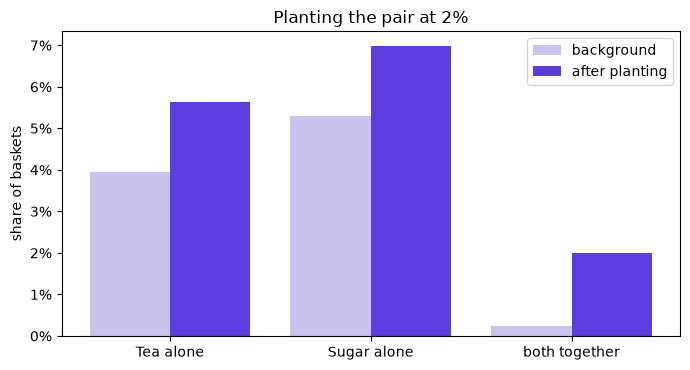

In [11]:
labels = ["Tea alone", "Sugar alone", "both together"]
before = [stats(baskets)[k] for k in ("Tea alone", "Sugar alone", "both")]
after = [stats(planted_baskets)[k] for k in ("Tea alone", "Sugar alone", "both")]

x = np.arange(3)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(x - 0.2, before, 0.4, label="background", color="#c9c3ee")
ax.bar(x + 0.2, after, 0.4, label="after planting", color="#5b3de0")
ax.set_xticks(x, labels)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_ylabel("share of baskets")
ax.legend()
ax.set_title("Planting the pair at 2%")
plt.tight_layout()
plt.show()

## What the exact miner sees

Itemsets up to size 3 at 0.1% support that contain the pair, before vs after:

In [12]:
def with_pair(data):
    found = frequent_itemsets(data, min_support=0.001, max_size=3)
    return {itemset: s for itemset, s in found.items() if wanted <= itemset}

before_found, after_found = with_pair(baskets), with_pair(planted_baskets)

print(f"itemsets holding both tea and sugar, at 0.1% support:")
print(f"   before planting: {len(before_found)}")
print(f"   after planting:  {len(after_found)}")
print("\nin the planted data:")
for itemset, s in sorted(after_found.items(), key=lambda kv: -kv[1])[:6]:
    extra = sorted(itemset - wanted)
    print(f"   {s:.2%}   tea + sugar" + (f" + {extra[0]}" if extra else "   (the planted pair itself)"))

itemsets holding both tea and sugar, at 0.1% support:
   before planting: 1
   after planting:  21

in the planted data:
   2.00%   tea + sugar   (the planted pair itself)
   0.22%   tea + sugar + Potato 1 kg
   0.22%   tea + sugar + Onion 1 kg
   0.21%   tea + sugar + Tomato 1 kg
   0.20%   tea + sugar + Gokul Fresh Milk 500 ml
   0.19%   tea + sugar + Coriander Leaves bunch


One planted pair → 21 frequent itemsets: the pair plus a crowd of triples (pair + any popular item) that clear the
threshold only because the pair is common. So the answer key can't just be "what we planted"; it has to be the exact
count of everything frequent, labelled by how it came about (sections 5 and 6).

## When planting refuses

In [13]:
tests = {
    "too common by chance (Onion + Potato at 0.5%)": Planted(("Onion 1 kg", "Potato 1 kg"), 0.005),
    "two SKUs of the same product": Planted(("Chai Chaska Tea Powder 250 g", "Chai Chaska Tea Powder 500 g"), 0.01),
    "an item the shop does not sell": Planted(("Chai Chaska Tea Powder 250 g", "Unicorn Milk 1 L"), 0.01),
    "support out of range": Planted((tea.name, sugar.name), 1.5),
}
for label, bad in tests.items():
    try:
        my_plant_itemset(baskets, bad, catalog)
    except ValueError as error:
        print(f"{label}\n    ValueError: {error}\n")

too common by chance (Onion + Potato at 0.5%)
    ValueError: 1309 baskets already hold this itemset by chance, more than the 500 asked for: it is too common to plant at support 0.005

two SKUs of the same product
    ValueError: a planted itemset needs different products: two of these are the same item or product

an item the shop does not sell
    ValueError: not in the catalogue: ['Unicorn Milk 1 L']

support out of range
    ValueError: support must be between 0 and 1, got 1.5



## Try it: a rare, surprising triple at 0.05%

In [14]:
rare = sorted(catalog, key=lambda item: shares[index[item.name]])
triple_items = []
seen_products = set()
for item in rare:
    if item.category in ("Personal Care", "Spices", "Beverages") and (item.category, item.base) not in seen_products:
        triple_items.append(item.name)
        seen_products.add((item.category, item.base))
    if len(triple_items) == 3:
        break

triple = Planted(tuple(triple_items), 0.0005, kind="surprising")
result = my_plant_itemset(baskets, triple, catalog, seed=2)

print(triple_items)
print(f"chance count before: {round(support_of(baskets, triple.items) * len(baskets))}; "
      f"after planting: {round(support_of(result, triple.items) * len(baskets))} baskets")

['Tulsi Tara Hair Oil 500 ml', 'Tulsi Tara Talcum Powder 200 g', 'Tadka Tales Rasam Powder 200 g']
chance count before: 0; after planting: 50 baskets


Three unrelated rare items, 50 baskets in 100,000. No internet prior would link them, so if the model finds them it
learned it from our baskets.

## What I built
`my_plant_itemset`: makes an itemset exactly as common as asked by topping up random baskets, swapping clashing SKUs,
adding quantities and reshuffling — identical to the reference, and it refuses impossible requests with a reason.

## Test yourself

**1. Why does planting only "top up" and refuse when chance already exceeds the target?**
Planting can only add items to baskets, never remove them. If chance already puts the set in more baskets than the
target, there's no way to bring the count down by adding, so the honest move is to raise an error.

**2. Why does the function swap out other SKUs of a planted product instead of just adding the planted item?**
Section 3 made sure a basket never holds two SKUs of the same product (two sugars). Adding Chai Chaska Sugar to a
basket that already has Amrit Pey Sugar would break that, so the other sugar is replaced.

**3. We planted one pair, so why does the miner find 21 itemsets containing it?**
Once the pair is in 2% of baskets, any popular item (in ~10% of baskets) lands with it in ~0.2% of them — above the
0.1% threshold. Those triples are real and frequent, just not planted, so the answer key must count everything.

## My notes

Planting is exact top-up: count what chance already gives, then add the pair to just enough random baskets to hit 2,000. Surprising: one planted pair created 20 extra frequent triples I never planted.